# 05-0d — GANs : des portraits adversariaux au moment NFT

**Navigation** : [↑ 05-History](README.md) | [← 05-0c : Low-complexity art](05-0c-Low-Complexity-Art-Python.ipynb) | [05-1 : DiscoDiffusion →](05-1-DiscoDiffusion-CLIP-Guided-Diffusion.ipynb)

> **Notebook rétrospectif — Racines pré-Stable-Diffusion.** Quatrième jalon de
> l'[Epic #16774](https://github.com/jsboige/CoursIA/issues/16774) : le moment où
> l'art génératif cesse d'écrire ses règles et les **apprend** d'un corpus. Les jalons
> précédents (moteurs symboliques, démoscène, low-complexity art) mesuraient une
> description courte qui engendre une image riche ; ce jalon mesure ce que coûte,
> et ce que risque, une description **apprise**.

**La thèse du notebook en une ligne** : un GAN est un programme génératif comme les
autres, mais sa description est un jeu de poids **plus lourd que son corpus**, et
la question qui a agité le marché de l'art (« qui est l'auteur ? ») a une moitié
mesurable : le générateur **copie-t-il** ses exemples ?

## Ce qui s'est passé, dans l'ordre

| Date | Événement | Source |
|---|---|---|
| 2014 | Goodfellow et al. publient les *Generative Adversarial Nets* : un générateur $G$ et un discriminateur $D$ jouent le jeu min-max $\min_G \max_D \; \mathbb{E}_x[\log D(x)] + \mathbb{E}_z[\log(1 - D(G(z)))]$ | [arXiv:1406.2661](https://arxiv.org/abs/1406.2661) |
| 2015 | Radford, Metz et Chintala donnent les **règles d'architecture** qui rendent l'entraînement convolutif stable (DCGAN) | [arXiv:1511.06434](https://arxiv.org/abs/1511.06434) |
| 25 oct. 2018 | *Edmond de Belamy, from La Famille de Belamy*, du collectif parisien Obvious, est adjugé **432 500 $** chez Christie's New York (estimation 7 000-10 000 $). Le GAN a été nourri de 15 000 portraits peints du XIVe au XXe siècle ; la « signature » en bas à droite est la formule min-max elle-même | [Christie's](https://www.christies.com/en/stories/a-collaboration-between-two-artists-one-human-one-a-machine-0cd01f4e232f4279a525a446d60d4cd1), [NYT](https://www.nytimes.com/2018/10/25/arts/design/ai-art-sold-christies.html) |
| oct. 2018 | Robbie Barrat, qui publiait sur GitHub du code et des réseaux pré-entraînés de portraits, indique que les sorties d'Obvious sont presque identiques à celles de ses modèles : la question d'auteur se déplace du réseau vers le code et le corpus | [The Verge](https://www.theverge.com/2018/10/23/18013190/ai-art-portrait-auction-christies-belamy-obvious-robbie-barrat-gans) |
| 2021 | Boom des NFT. Les ventes génératives les plus spectaculaires ne sont pas des GANs mais des **programmes** : *Fidenza* de Tyler Hobbs (Art Blocks), dont l'exemplaire #313 se revend 1 000 ETH (environ 3,3 M$) en août 2021 | [Hypebeast](https://hypebeast.com/2021/8/art-blocks-fidenza-nft-1400-to-3-million-ethereum), [Texas Monthly](https://www.texasmonthly.com/arts-entertainment/art-blocks-generative-artists/) |

Le rapprochement « GANs vendus à prix d'or à l'époque des NFT » condense donc deux
moments distincts : la vente GAN de référence précède de trois ans le boom NFT, et
ce boom a surtout couronné l'art génératif **par code**, c'est-à-dire l'héritier
direct des moteurs symboliques du jalon 1. Le notebook garde la technique et laisse
le marché à sa chronologie.

## Ce que le notebook exécute

1. Un **DCGAN** conforme aux règles de Radford et al., entraîné sur 400 portraits
   (base Olivetti, AT&T Laboratories Cambridge, 40 personnes × 10 photos).
2. **La question de la copie**, posée comme une expérience contrôlée : chaque
   personne a une photo vue à l'entraînement et une photo jamais vue. Un générateur
   qui copie produit des images plus proches des photos vues.
3. **L'empreinte spectrale** : Durall et al. (CVPR 2020) affirment que le
   suréchantillonnage convolutif empêche les GANs de reproduire le spectre des
   images naturelles, au point de les détecter « jusqu'à 100 % ». On le mesure.
4. **La longueur de description**, dans le fil des jalons 1 à 3 : la taille du
   générateur contre celle du corpus compressé.

Le mode collapse sur un mélange de gaussiennes 2D n'est pas refait ici : il est
mesuré dans [ML 3.6b](../../../ML/DataScienceWithAgents/03-Deep-Learning/3.6b-Modeles-Generatifs-PyTorch.ipynb),
qui compare GAN, VAE et diffusion sur la même cible.

**Durée** : environ 6 minutes sur un GPU portable (RTX 4060), nettement plus sur
CPU (le notebook choisit le périphérique seul). Les chiffres cités dans les lectures
proviennent de l'exécution GPU committée ; une exécution CPU donne des valeurs
voisines, pas identiques.

torch 2.14.0+cu126 | peripherique : cuda | NVIDIA GeForce RTX 4060 Laptop GPU
corpus complet : (400, 1, 32, 32) | entrainement : (360, 1, 32, 32) | couple de controle : 40 photos vues / 40 jamais vues


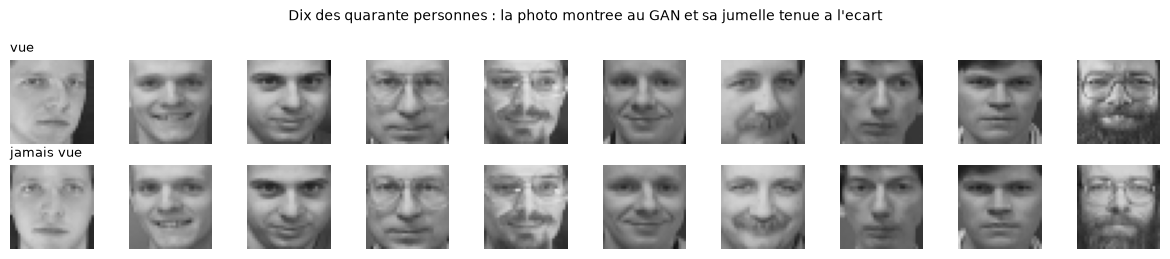

In [1]:
import os, time, lzma
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_olivetti_faces
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

%matplotlib inline
torch.use_deterministic_algorithms(True, warn_only=True)
torch.backends.cudnn.benchmark = False
DEV = "cuda" if torch.cuda.is_available() else "cpu"
print("torch", torch.__version__, "| peripherique :", DEV,
      "|", torch.cuda.get_device_name(0) if DEV == "cuda" else "CPU")

faces = fetch_olivetti_faces()                       # 400 x 64 x 64, valeurs dans [0, 1]
X = F.interpolate(torch.tensor(faces.images)[:, None], size=32, mode="area") * 2 - 1
ids = faces.target
vue = np.array([np.where(ids == k)[0][1] for k in range(40)])     # 2e photo de chaque personne
non_vue = np.array([np.where(ids == k)[0][0] for k in range(40)]) # 1re photo, jamais montree
mask_train = np.ones(400, bool); mask_train[non_vue] = False
X_train360 = X[mask_train]          # 9 photos par personne, dont la photo "vue"
X_vue, X_non_vue = X[vue], X[non_vue]
print("corpus complet :", tuple(X.shape), "| entrainement :", tuple(X_train360.shape),
      "| couple de controle :", len(X_vue), "photos vues /", len(X_non_vue), "jamais vues")

fig, ax = plt.subplots(2, 10, figsize=(12, 2.6))
for j, k in enumerate(range(0, 40, 4)):
    ax[0, j].imshow(X_vue[k, 0], cmap="gray", vmin=-1, vmax=1)
    ax[1, j].imshow(X_non_vue[k, 0], cmap="gray", vmin=-1, vmax=1)
    ax[0, j].axis("off"); ax[1, j].axis("off")
ax[0, 0].set_title("vue", fontsize=9, loc="left"); ax[1, 0].set_title("jamais vue", fontsize=9, loc="left")
plt.suptitle("Dix des quarante personnes : la photo montree au GAN et sa jumelle tenue a l'ecart", fontsize=10)
plt.tight_layout(); plt.show()

### Lecture : 400 portraits, dont 360 vus et 40 jamais vus

Le corpus compte 400 portraits ramenés à 32×32 pixels. Le GAN en voit 360 : neuf photos par personne, dont la photo « vue » de la ligne du haut. La photo du bas, prise lors d'une autre séance, n'entre jamais dans l'entraînement. Les deux photos d'une même personne se ressemblent davantage qu'elles ne ressemblent aux autres personnes, et c'est ce qui rend le contrôle de la section 3 honnête : toute préférence d'un échantillon pour la photo vue ne peut pas venir de l'identité, puisque les deux photos la partagent.

## 1. Le DCGAN : cinq règles d'architecture

Radford et al. (§3) résument ce qui rend stable un GAN convolutif :

- remplacer le *pooling* par des convolutions à pas (discriminateur) et des
  convolutions **transposées** (générateur) ;
- BatchNorm dans les deux réseaux ;
- pas de couche dense cachée ;
- ReLU dans le générateur, sauf la sortie en `tanh` ;
- LeakyReLU dans le discriminateur ;
- Adam avec un pas de $2\cdot10^{-4}$ et $\beta_1 = 0{,}5$ (§4, la valeur 0,9 faisait osciller l'entraînement).

Le générateur ci-dessous accepte une seconde façon de suréchantillonner (voisin le
plus proche puis convolution), qui servira au test spectral de la section 4.

In [2]:
Z = 64

class Generateur(nn.Module):
    def __init__(self, up="transposee"):
        super().__init__()
        def bloc(i, o, derniere=False):
            if up == "transposee":
                conv = nn.ConvTranspose2d(i, o, 4, 2, 1, bias=derniere)
            else:   # voisin le plus proche puis convolution 3x3
                conv = nn.Sequential(nn.Upsample(scale_factor=2, mode="nearest"),
                                     nn.Conv2d(i, o, 3, 1, 1, bias=derniere))
            return [conv] + ([nn.Tanh()] if derniere else [nn.BatchNorm2d(o), nn.ReLU(True)])
        self.net = nn.Sequential(
            nn.ConvTranspose2d(Z, 128, 4, 1, 0, bias=False), nn.BatchNorm2d(128), nn.ReLU(True),  # 1 -> 4
            *bloc(128, 64), *bloc(64, 32), *bloc(32, 1, derniere=True))                            # 4 -> 32
    def forward(self, z):
        return self.net(z[:, :, None, None])

class Discriminateur(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 32, 4, 2, 1), nn.LeakyReLU(0.2, True),
            nn.Conv2d(32, 64, 4, 2, 1, bias=False), nn.BatchNorm2d(64), nn.LeakyReLU(0.2, True),
            nn.Conv2d(64, 128, 4, 2, 1, bias=False), nn.BatchNorm2d(128), nn.LeakyReLU(0.2, True),
            nn.Conv2d(128, 1, 4, 1, 0))
    def forward(self, x):
        return self.net(x).view(-1)

def n_params(m):
    return sum(p.numel() for p in m.parameters())

for up in ["transposee", "voisin"]:
    print(f"generateur ({up:10s}) : {n_params(Generateur(up)):>7,d} parametres".replace(",", " "))
print(f"discriminateur          : {n_params(Discriminateur()):>7,d} parametres".replace(",", " "))

generateur (transposee) : 295 873 parametres
generateur (voisin    ) : 223 969 parametres
discriminateur          : 166 817 parametres


### Lecture : 295 873 paramètres pour le générateur, 166 817 pour le discriminateur

Le générateur à convolutions transposées compte 295 873 paramètres, la variante « voisin puis convolution » 223 969 (un noyau 3×3 au lieu de 4×4 à chaque étage), le discriminateur 166 817. Ces nombres reviennent en section 6 : ils fixent la longueur de description du programme génératif.

## 2. Entraîner le jeu min-max

La boucle suit Goodfellow et al. avec la perte **non saturante** du générateur
(maximiser $\log D(G(z))$ plutôt que minimiser $\log(1-D(G(z)))$, §3 du papier : le
gradient ne s'éteint pas quand le discriminateur gagne trop tôt).

Un détail qui coûte cher s'il est oublié : on **échantillonne en mode entraînement**.
En mode `eval`, la BatchNorm du générateur utilise ses moyennes glissantes, qui ne
suivent pas un générateur en mouvement ; sur ce montage, les visages deviennent alors
une texture bruitée. Le prototype de ce notebook est tombé dans ce piège avant
d'être corrigé.

entrainement principal : 2500 iterations en 43 s
perte D  : debut 0.201 -> fin 0.080
perte G  : debut 3.392 -> fin 3.874


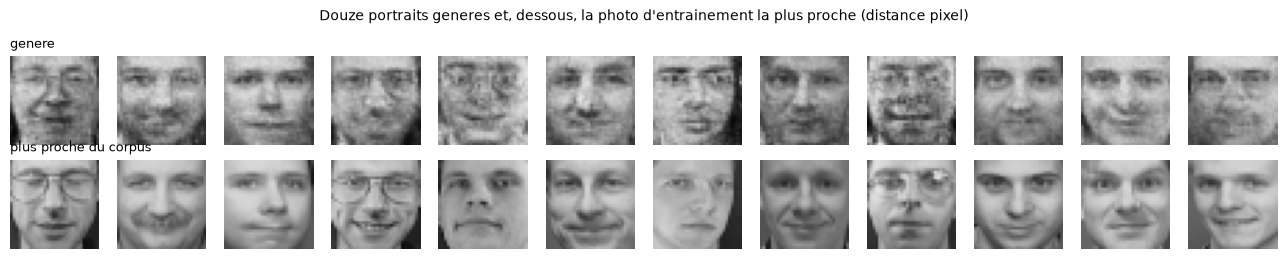

In [3]:
ITERS, BATCH = 2500, 64
Z_FIXE = torch.randn(400, Z, generator=torch.Generator().manual_seed(1234))

def entrainer(Xt, up="transposee", graine=0, iters=ITERS):
    torch.manual_seed(graine); np.random.seed(graine)
    g, d = Generateur(up).to(DEV), Discriminateur().to(DEV)
    og = torch.optim.Adam(g.parameters(), 2e-4, betas=(0.5, 0.999))
    od = torch.optim.Adam(d.parameters(), 2e-4, betas=(0.5, 0.999))
    bce = nn.BCEWithLogitsLoss()
    un, zero = torch.ones(BATCH, device=DEV), torch.zeros(BATCH, device=DEV)
    Xt = Xt.to(DEV); pertes = []
    for it in range(iters):
        x = Xt[torch.randint(0, len(Xt), (BATCH,), device=DEV)]
        faux = g(torch.randn(BATCH, Z, device=DEV))
        ld = bce(d(x), un) + bce(d(faux.detach()), zero)
        od.zero_grad(); ld.backward(); od.step()
        lg = bce(d(faux), un)                              # perte non saturante
        og.zero_grad(); lg.backward(); og.step()
        pertes.append((ld.item(), lg.item()))
    with torch.no_grad():
        echantillons = g(Z_FIXE.to(DEV)).cpu()             # mode entrainement : stats du lot
    return g, echantillons, np.array(pertes)

t0 = time.time()
G_principal, S_principal, pertes = entrainer(X_train360, "transposee", graine=0)
print(f"entrainement principal : {ITERS} iterations en {time.time() - t0:.0f} s")
print(f"perte D  : debut {pertes[:100, 0].mean():.3f} -> fin {pertes[-100:, 0].mean():.3f}")
print(f"perte G  : debut {pertes[:100, 1].mean():.3f} -> fin {pertes[-100:, 1].mean():.3f}")

def plus_proche(S, R):
    dist = torch.cdist(S.flatten(1), R.flatten(1))
    return dist.min(1).values, dist.argmin(1)

_, idx = plus_proche(S_principal[:12], X_train360)
fig, ax = plt.subplots(2, 12, figsize=(13, 2.6))
for i in range(12):
    ax[0, i].imshow(S_principal[i, 0], cmap="gray", vmin=-1, vmax=1)
    ax[1, i].imshow(X_train360[idx[i], 0], cmap="gray", vmin=-1, vmax=1)
    ax[0, i].axis("off"); ax[1, i].axis("off")
ax[0, 0].set_title("genere", fontsize=9, loc="left"); ax[1, 0].set_title("plus proche du corpus", fontsize=9, loc="left")
plt.suptitle("Douze portraits generes et, dessous, la photo d'entrainement la plus proche (distance pixel)", fontsize=10)
plt.tight_layout(); plt.show()

### Lecture : le discriminateur gagne le jeu, la perte du générateur monte

L'entraînement principal prend moins d'une minute sur le GPU. Les pertes ne racontent pas une convergence : celle du discriminateur baisse (0,201 → 0,080 en moyenne sur 100 itérations) pendant que celle du générateur monte (3,392 → 3,874). Le discriminateur gagne le jeu, ce qui est l'état ordinaire d'un GAN et la raison pour laquelle sa courbe de perte ne sert pas de critère d'arrêt.

Les échantillons sont pourtant des visages : yeux, nez, bouche, lunettes, pose frontale et cadrage de la base. On y voit aussi le style reconnaissable des GANs d'époque : des textures granuleuses, des taches là où les lunettes se mêlent au visage, des symétries approximatives. Ce sont les « distorsions » qu'Obvious revendiquait comme un attribut du modèle. Les photos placées dessous sont les voisines les plus proches en distance pixel : sur cette grille, elles ressemblent aux échantillons par la pose, l'éclairage ou les lunettes, sans en être des copies.

## 3. Le générateur copie-t-il ?

La question d'auteur soulevée par la vente de 2018 a une moitié qui se mesure. Si
un générateur recopie ses exemples, ses images sont plus proches des photos **qu'il
a vues** que d'autres photos des **mêmes personnes** qu'il n'a jamais vues. Le couple
(vue, jamais vue) neutralise l'identité : seule la mémorisation peut faire pencher
la balance.

Pour chaque échantillon, on compare sa distance à la photo vue la plus proche et à
la photo jamais vue la plus proche (40 de chaque côté). Sans mémorisation, la
fraction d'échantillons plus proches du côté « vu » vaut environ 1/2.

Trois montages, trois graines chacun (0, 1, 42) :

- **360 portraits**, suréchantillonnage par convolution transposée ;
- **360 portraits**, voisin le plus proche puis convolution ;
- **40 portraits** seulement, une photo par personne : le corpus de *Belamy* était
  375 fois plus grand que celui-ci.

In [4]:
MONTAGES = [("360 portraits, transposee", X_train360, "transposee"),
            ("360 portraits, voisin",     X_train360, "voisin"),
            ("40 portraits, transposee",  X_vue,      "transposee")]
GRAINES = [0, 1, 42]

resultats, echantillons = [], {}
t0 = time.time()
for nom, Xt, up in MONTAGES:
    for graine in GRAINES:
        if nom.startswith("360 portraits, transposee") and graine == 0:
            S = S_principal                                  # deja entraine en section 2
        else:
            _, S, _ = entrainer(Xt, up, graine)
        echantillons[(nom, graine)] = S
        d_vue, _ = plus_proche(S, X_vue)
        d_non_vue, _ = plus_proche(S, X_non_vue)
        resultats.append(dict(montage=nom, graine=graine,
                              d_vue=d_vue.median().item(), d_non_vue=d_non_vue.median().item(),
                              penche_vu=(d_vue < d_non_vue).float().mean().item()))
print(f"{len(resultats)} entrainements mesures en {time.time() - t0:.0f} s\n")

print(f"{'montage':28s} {'graine':>6s} {'med. dist. vue':>15s} {'med. dist. jamais vue':>22s} {'fraction penchant vers vu':>26s}")
for r in resultats:
    print(f"{r['montage']:28s} {r['graine']:>6d} {r['d_vue']:>15.2f} {r['d_non_vue']:>22.2f} {r['penche_vu']:>26.3f}")
print()
for nom, _, _ in MONTAGES:
    v = np.array([r["penche_vu"] for r in resultats if r["montage"] == nom])
    print(f"{nom:28s} fraction penchant vers vu : moyenne {v.mean():.3f}, ecart-type {v.std(ddof=1):.3f}")

9 entrainements mesures en 348 s

montage                      graine  med. dist. vue  med. dist. jamais vue  fraction penchant vers vu
360 portraits, transposee         0            7.75                   7.88                      0.553
360 portraits, transposee         1            7.82                   7.87                      0.505
360 portraits, transposee        42            7.88                   7.96                      0.527
360 portraits, voisin             0            7.77                   7.72                      0.498
360 portraits, voisin             1            7.75                   7.74                      0.485
360 portraits, voisin            42            7.92                   7.85                      0.510
40 portraits, transposee          0            7.29                   7.71                      0.720
40 portraits, transposee          1            7.07                   7.53                      0.757
40 portraits, transposee         42            7

### Lecture : pas de copie mesurable à 360 portraits, copie nette à 40

Les trois graines suffisent à séparer deux régimes.

- **Avec 360 portraits, pas de copie mesurable.** La fraction d'échantillons plus proches de la photo vue vaut 0,528 en moyenne (écart-type 0,024) avec les convolutions transposées et 0,498 (écart-type 0,012) avec le voisin le plus proche, soit le hasard à quelques centièmes près. Les distances médianes aux photos vues et jamais vues diffèrent au plus de 0,13.
- **Avec 40 portraits, la copie apparaît.** La fraction monte à 0,720 en moyenne (écart-type 0,037), et à chaque graine la distance médiane à la photo vue est plus petite que la distance à la photo jamais vue (7,29 contre 7,71, 7,07 contre 7,53, 7,63 contre 7,89). Avec une seule photo par personne, le générateur s'approche des photos qu'il a vues plutôt que des visages en général.

La question d'auteur de 2018 a donc une moitié mesurable, et sa réponse dépend du rapport entre la capacité du générateur et la taille du corpus. Ce montage ne dit rien du cas *Belamy* lui-même : 15 000 portraits, soit 375 fois notre petit corpus, un autre réseau et une autre résolution. Il montre seulement que la question se mesure, et comment.

## 4. L'empreinte spectrale

Durall, Keuper et Keuper (CVPR 2020) affirment que le suréchantillonnage
convolutif empêche un générateur de reproduire la distribution spectrale des
images naturelles, et qu'un simple classifieur sur le spectre détecte les images
générées « jusqu'à 100 % » sur les bancs publics. On mesure les deux moitiés :

- le **profil radial** du spectre de puissance (moyenne azimutale de $|\hat{x}|^2$,
  en log10), réel contre généré ;
- un **détecteur** : régression logistique sur ce profil (17 valeurs par image),
  400 portraits réels contre 400 générés, précision en validation croisée à 5 plis.
  0,5 = indiscernable.

montage                      graine  precision du detecteur  exces hautes freq. (log10)


360 portraits, transposee         0                   0.643                       0.083


360 portraits, transposee         1                   0.626                       0.065


360 portraits, transposee        42                   0.655                       0.057
360 portraits, voisin             0                   0.710                       0.083


360 portraits, voisin             1                   0.764                       0.093
360 portraits, voisin            42                   0.711                       0.084


40 portraits, transposee          0                   0.912                       0.224
40 portraits, transposee          1                   0.875                       0.174


40 portraits, transposee         42                   0.831                       0.184

360 portraits, transposee    detecteur : moyenne 0.641, min 0.626, max 0.655
360 portraits, voisin        detecteur : moyenne 0.728, min 0.710, max 0.764
40 portraits, transposee     detecteur : moyenne 0.873, min 0.831, max 0.912


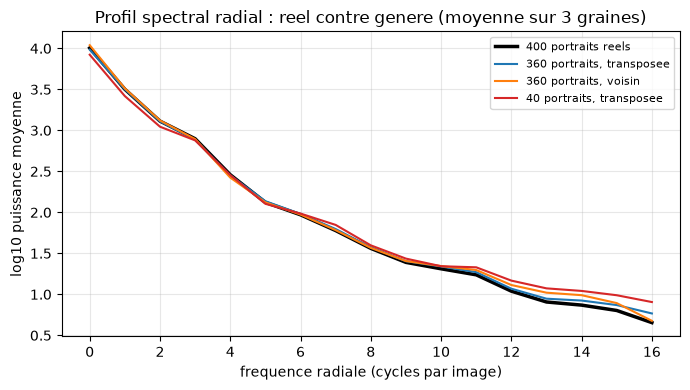

In [5]:
def profil_radial(imgs):
    x = imgs.squeeze(1).numpy()
    P = np.abs(np.fft.fftshift(np.fft.fft2(x), axes=(-2, -1))) ** 2
    n = x.shape[-1]
    yy, xx = np.indices((n, n))
    r = np.hypot(yy - n / 2, xx - n / 2).astype(int)
    prof = np.stack([np.bincount(r.ravel(), p.ravel()) / np.bincount(r.ravel()) for p in P])
    return np.log10(prof[:, : n // 2 + 1])

P_reel = profil_radial(X)

def detecter(S):
    feats = np.vstack([P_reel, profil_radial(S)])
    y = np.r_[np.zeros(len(P_reel)), np.ones(len(S))]
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
    return cross_val_score(clf, feats, y, cv=5).mean()

print(f"{'montage':28s} {'graine':>6s} {'precision du detecteur':>23s} {'exces hautes freq. (log10)':>27s}")
for r in resultats:
    S = echantillons[(r["montage"], r["graine"])]
    r["detect"] = detecter(S)
    r["exces_hf"] = (profil_radial(S).mean(0) - P_reel.mean(0))[-4:].mean()
    print(f"{r['montage']:28s} {r['graine']:>6d} {r['detect']:>23.3f} {r['exces_hf']:>27.3f}")
print()
for nom, _, _ in MONTAGES:
    v = np.array([r["detect"] for r in resultats if r["montage"] == nom])
    print(f"{nom:28s} detecteur : moyenne {v.mean():.3f}, min {v.min():.3f}, max {v.max():.3f}")

freqs = np.arange(P_reel.shape[1])
plt.figure(figsize=(7, 4))
plt.plot(freqs, P_reel.mean(0), "k-", lw=2.5, label="400 portraits reels")
for (nom, _, _), c in zip(MONTAGES, ["C0", "C1", "C3"]):
    prof = np.mean([profil_radial(echantillons[(nom, g)]).mean(0) for g in GRAINES], axis=0)
    plt.plot(freqs, prof, color=c, lw=1.5, label=nom)
plt.xlabel("frequence radiale (cycles par image)"); plt.ylabel("log10 puissance moyenne")
plt.title("Profil spectral radial : reel contre genere (moyenne sur 3 graines)")
plt.legend(fontsize=8); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

### Lecture : une empreinte spectrale qui survit au changement d'opérateur

La courbe confirme l'observation de Durall et al. dans sa direction : les profils générés suivent le réel aux basses fréquences et s'en écartent vers le haut du spectre, où ils portent trop d'énergie. L'excès sur les quatre dernières fréquences va de 0,057 à 0,093 (en log10) pour les montages à 360 portraits et de 0,174 à 0,224 pour le montage à 40 portraits.

Le détecteur, lui, ne reproduit pas les « jusqu'à 100 % » du papier à cette échelle. Sa précision moyenne vaut 0,641 pour les convolutions transposées et 0,728 pour le voisin le plus proche, contre 0,873 pour le montage à 40 portraits. Trois écarts avec la lecture naïve du papier sont à retenir.

1. Sur des images de 32×32, le profil radial n'a que 17 valeurs, et le signal tient dans les dernières.
2. Remplacer la convolution transposée par le voisin le plus proche **n'efface pas** l'empreinte : ici, elle est même un peu plus détectable (0,728 contre 0,641). L'artefact n'appartient donc pas à un seul opérateur de suréchantillonnage.
3. Le générateur le plus détectable est celui qui copie le plus. Peu de données donnent à la fois plus de mémorisation et une signature spectrale plus nette.

## 5. Le geste qui a fait l'esthétique GAN : l'interpolation latente

Le style reconnaissable des GANs d'époque tient autant à leurs défauts qu'à un
geste : **marcher dans l'espace latent**. Entre deux vecteurs $z_a$ et $z_b$, le
générateur produit une suite continue de visages qui n'existent pas, ce que les
artistes du GAN ont exploité en vidéo et en séries. Radford et al. (§6.1) en font
même un test : une marche latente sans saut brusque indique un générateur qui n'a
pas simplement mémorisé des points isolés.

ecart pixel entre deux pas successifs : [2.32 2.7  2.86 2.59 2.33 1.79 1.51 1.36]
plus grand saut / saut median : 1.23


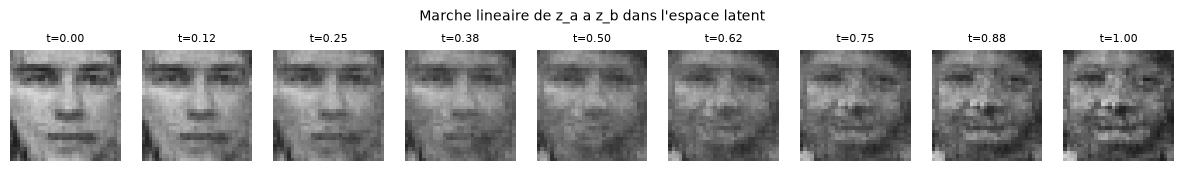

In [6]:
torch.manual_seed(7)
za, zb = torch.randn(1, Z), torch.randn(1, Z)
t = torch.linspace(0, 1, 9)[:, None]
lot = torch.cat([(1 - t) * za + t * zb, torch.randn(55, Z)])     # le lot complete les stats de BatchNorm
with torch.no_grad():
    marche = G_principal(lot.to(DEV)).cpu()[:9]
sauts = (marche[1:] - marche[:-1]).flatten(1).norm(dim=1)
print("ecart pixel entre deux pas successifs :", np.round(sauts.numpy(), 2))
print(f"plus grand saut / saut median : {sauts.max().item() / sauts.median().item():.2f}")

fig, ax = plt.subplots(1, 9, figsize=(12, 1.7))
for i in range(9):
    ax[i].imshow(marche[i, 0], cmap="gray", vmin=-1, vmax=1); ax[i].axis("off")
    ax[i].set_title(f"t={t[i, 0]:.2f}", fontsize=8)
plt.suptitle("Marche lineaire de z_a a z_b dans l'espace latent", fontsize=10)
plt.tight_layout(); plt.show()

### Lecture : l'interpolation latente reste continue d'un visage à l'autre

La marche latente passe d'un visage à un autre sans saut. L'écart pixel entre deux pas successifs reste entre 1,36 et 2,86, et le plus grand saut ne vaut que 1,23 fois le saut médian. Le générateur n'a pas appris une table de points isolés, ce qui recoupe la section 3 (pas de copie à 360 portraits).

Visuellement, l'interpolation traverse des visages intermédiaires qui n'existent dans aucune photo, avec les textures et les taches typiques du modèle. C'est ce matériau que les artistes du GAN ont mis en série et en vidéo.

## 6. La longueur de description, au retour du fil

Les jalons 1 à 3 mesuraient un **petit programme** qui engendre une **grande image**.
On pose la même mesure au GAN : combien d'octets faut-il pour décrire le générateur,
et combien pour décrire le corpus qu'il imite ?

In [7]:
octets_G = n_params(G_principal) * 4                    # poids en float32
corpus_u8 = ((X_train360 + 1) / 2 * 255).round().clamp(0, 255).byte().numpy().tobytes()
corpus_lzma = len(lzma.compress(corpus_u8, preset=9))

print(f"generateur (float32)         : {octets_G:>9,d} octets".replace(",", " "))
print(f"corpus de 360 portraits brut : {len(corpus_u8):>9,d} octets".replace(",", " "))
print(f"corpus compresse (LZMA -9)   : {corpus_lzma:>9,d} octets".replace(",", " "))
print(f"generateur / corpus compresse : x{octets_G / corpus_lzma:.2f}")
print(f"une image 32x32 en niveaux de gris : {32 * 32} octets ; "
      f"le generateur en decrit 'une infinite', mais pese autant que {octets_G // (32 * 32)} images brutes")

generateur (float32)         : 1 183 492 octets
corpus de 360 portraits brut :   368 640 octets
corpus compresse (LZMA -9)   :   286 312 octets
generateur / corpus compresse : x4.13
une image 32x32 en niveaux de gris : 1024 octets ; le generateur en decrit 'une infinite', mais pese autant que 1155 images brutes


### Lecture : le générateur pèse 4,13 fois plus que le corpus qu'il imite

Le générateur pèse 1 183 492 octets en float32, et le corpus qu'il imite 368 640 octets brut ou 286 312 octets compressé par LZMA. Le programme génératif est donc **4,13 fois plus lourd** que les données qu'il résume.

C'est l'inverse exact de la démoscène et du low-complexity art des jalons 2 et 3, où quelques centaines d'octets engendraient une image riche. Le générateur peut certes produire une infinité de portraits, mais sa description vaut 1 155 images brutes, plus de trois fois le corpus. Ce qu'il a gagné ne se mesure pas en compression : il échantillonne des visages **nouveaux**, que le corpus ne contient pas. L'exercice 3 demande de combien on peut réduire cet écart.

## Exercices

### Exercice 1 — Un détecteur de copie plus fin

La fraction « penchant vers vu » regarde la photo la plus proche de chaque côté.
Un critère classique de détection de copie regarde plutôt le **rapport** $d_1/d_2$
entre la distance à la photo d'entraînement la plus proche et à la deuxième plus
proche : une copie quasi exacte donne un rapport très petit.

Calculez la distribution de $d_1/d_2$ (sur `X_vue`) pour les échantillons du montage
« 40 portraits » et du montage « 360 portraits, transposee » (graine 0), et dites si
ce critère sépare mieux les deux montages que la fraction de la section 3.

In [8]:
# Exercice 1 -- rapport d1/d2 contre le corpus vu
# Indice : torch.cdist(S.flatten(1), X_vue.flatten(1)).topk(2, largest=False) donne d1 et d2
S40 = echantillons[("40 portraits, transposee", 0)]
S360 = echantillons[("360 portraits, transposee", 0)]
rapport_40 = None   # TODO etudiant
rapport_360 = None  # TODO etudiant
print("Exercice a completer : comparer les medianes de d1/d2 pour les deux montages")

Exercice a completer : comparer les medianes de d1/d2 pour les deux montages


### Exercice 2 — Plus longtemps, plus de copie ?

La mémorisation dépend aussi de la durée d'entraînement. Réentraînez le montage
« 40 portraits » (graine 0) pour 500, 1 500 et 2 500 itérations (`entrainer(X_vue,
"transposee", 0, iters=...)`), et tracez la fraction « penchant vers vu » en
fonction du nombre d'itérations. La copie apparaît-elle d'un coup ou
progressivement ?

In [9]:
# Exercice 2 -- fraction "penchant vers vu" en fonction de la duree d'entrainement
budgets = [500, 1500, 2500]
fractions = []   # TODO etudiant : une valeur par budget
print("Exercice a completer : entrainer pour chaque budget et mesurer la fraction")

Exercice a completer : entrainer pour chaque budget et mesurer la fraction


### Exercice 3 — Compresser le générateur

La section 6 compte les poids en float32. Quantifiez les poids du générateur sur
8 bits (par tenseur : $w \mapsto \mathrm{round}((w - \min)/(\max - \min) \cdot 255)$,
puis l'inverse), générez à nouveau les 400 échantillons de `Z_FIXE`, et mesurez
(a) la nouvelle longueur de description, (b) l'écart pixel moyen avec les
échantillons d'origine. Le générateur passe-t-il sous la taille du corpus
compressé ?

In [10]:
# Exercice 3 -- quantification 8 bits du generateur
import copy
G_q = copy.deepcopy(G_principal)
# TODO etudiant : quantifier puis dequantifier chaque tenseur de G_q.parameters()
octets_q = None   # TODO etudiant
print("Exercice a completer : quantifier, regenerer, comparer a corpus_lzma")

Exercice a completer : quantifier, regenerer, comparer a corpus_lzma


## Références

- I. Goodfellow, J. Pouget-Abadie, M. Mirza, B. Xu, D. Warde-Farley, S. Ozair, A. Courville, Y. Bengio, *Generative Adversarial Nets*, NeurIPS 2014. [arXiv:1406.2661](https://arxiv.org/abs/1406.2661)
- A. Radford, L. Metz, S. Chintala, *Unsupervised Representation Learning with Deep Convolutional Generative Adversarial Networks*, ICLR 2016. [arXiv:1511.06434](https://arxiv.org/abs/1511.06434)
- R. Durall, M. Keuper, J. Keuper, *Watch your Up-Convolution: CNN Based Generative Deep Neural Networks are Failing to Reproduce Spectral Distributions*, CVPR 2020. [arXiv:2003.01826](https://arxiv.org/abs/2003.01826)
- F. Samaria, A. Harter, *Parameterisation of a stochastic model for human face identification*, IEEE WACV 1994 (base Olivetti / AT&T, via `sklearn.datasets.fetch_olivetti_faces`).
- Christie's, *Obvious and the interface between art and artificial intelligence* (2018) ; The Verge, *How three French students used borrowed code to put the first AI portrait in Christie's* (23 oct. 2018) ; Hypebeast, *Art Block Bought for $1,400 Sells at $3.3 Million USD* (août 2021).

Copies lues pour ce carnet, dans le gisement partagé — les trois articles techniques ci-dessus y sont archivés, comme le veut la règle bibliographique du rayon :

- `G:\Mon Drive\MyIA\IA\Bibliographie IA\MachineLearning\2014 - Goodfellow et al - Generative Adversarial Nets.pdf`
- `G:\Mon Drive\MyIA\IA\Bibliographie IA\MachineLearning\2015 - Radford Metz Chintala - DCGAN - Unsupervised Representation Learning with Deep Convolutional GANs.pdf`
- `G:\Mon Drive\MyIA\IA\Bibliographie IA\MachineLearning\2020 - Durall Keuper Keuper - Watch your Up-Convolution.pdf`

**Rattachements** : Epic #16774 (jalon 4) · [ML 3.6b](../../../ML/DataScienceWithAgents/03-Deep-Learning/3.6b-Modeles-Generatifs-PyTorch.ipynb) pour le mode collapse.